# Track B: Time Series Data Visualization
**Author:** Mohammed Ghannam Alyami  
**Project:** VOLTA — Energy Pressure Forecasting  
**Task:** Exploratory Data Analysis (EDA) & Trend Analysis  

---
### Objective
Analyze time-series trends, seasonality, daily/weekly patterns, and anomalies across the four main targets:
1. Electricity Demand (`total load actual`)
2. Price (`price actual`)
3. Renewable Generation
4. Fossil Generation

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

# Load energy dataset and parse dates
energy_path = '../data/energy_dataset.csv'
df = pd.read_csv(energy_path)

# Convert timestamp column to datetime index
df['time'] = pd.to_datetime(df['time'], utc=True)
df = df.sort_values('time').set_index('time')

# Aggregate renewable and fossil generation columns
renewable_cols = [c for c in df.columns if any(k in c.lower() for k in ['solar', 'wind', 'hydro'])]
fossil_cols = [c for c in df.columns if any(k in c.lower() for k in ['fossil', 'gas', 'coal', 'oil'])]

df['renewable_total'] = df[renewable_cols].sum(axis=1)
df['fossil_total'] = df[fossil_cols].sum(axis=1)

print("Data successfully loaded!")
print(f"Time Period: {df.index.min()} to {df.index.max()}")

Data successfully loaded!
Time Period: 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00


## 1. Long-term Trends (2015 – 2018)
*Question:* Is there a long-term increase or decrease in Price and Demand over the 4-year period?

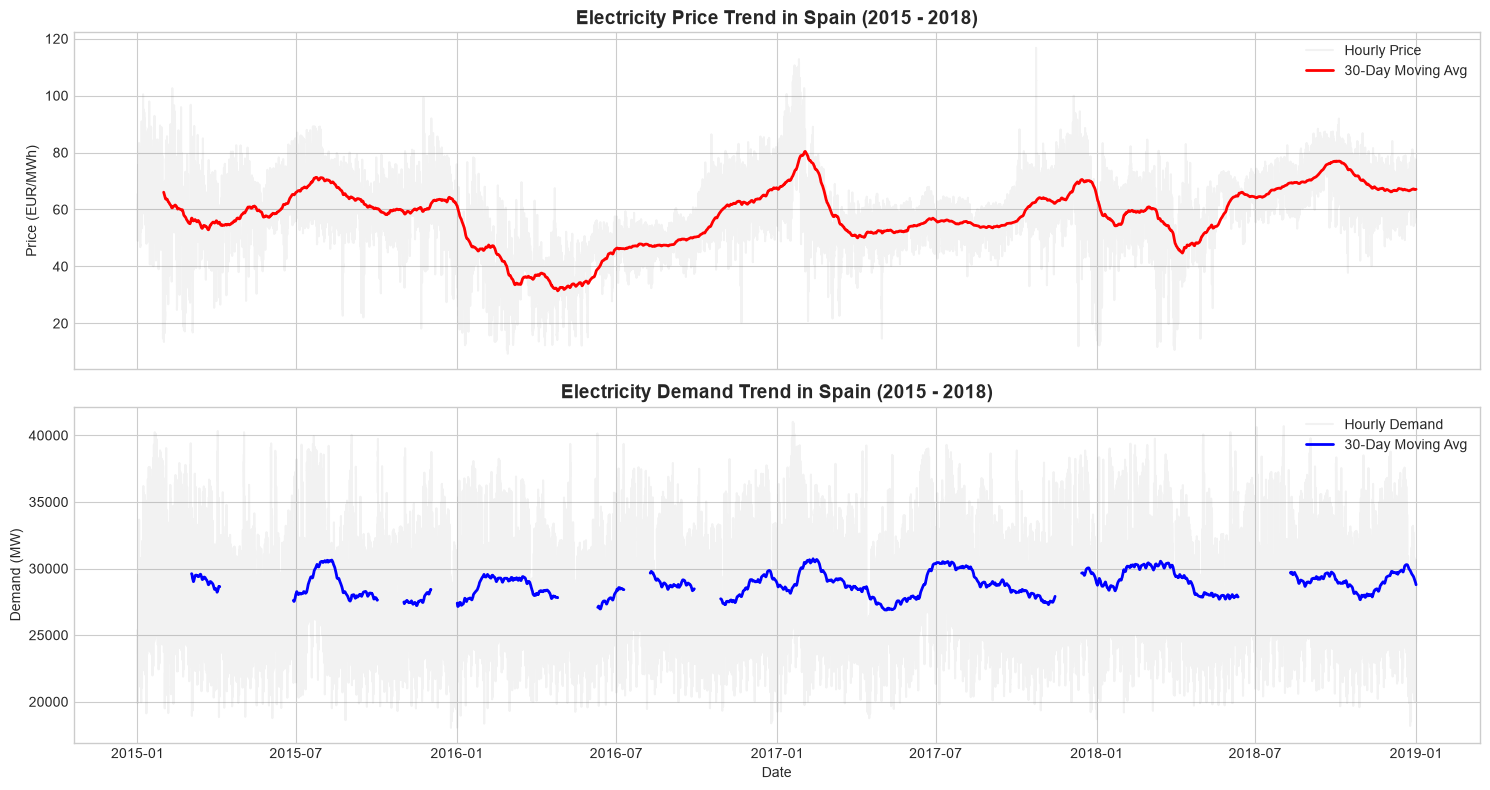

In [8]:
# Plot Electricity Price and Demand with 30-day moving average
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# 1. Electricity Price Trend
axes[0].plot(df['price actual'], alpha=0.1, color='gray', label='Hourly Price')
axes[0].plot(df['price actual'].rolling(window=24*30).mean(), color='red', linewidth=2, label='30-Day Moving Avg')
axes[0].set_title('Electricity Price Trend in Spain (2015 - 2018)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price (EUR/MWh)')
axes[0].legend()

# 2. Electricity Demand Trend
axes[1].plot(df['total load actual'], alpha=0.1, color='gray', label='Hourly Demand')
axes[1].plot(df['total load actual'].rolling(window=24*30).mean(), color='blue', linewidth=2, label='30-Day Moving Avg')
axes[1].set_title('Electricity Demand Trend in Spain (2015 - 2018)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Demand (MW)')
axes[1].set_xlabel('Date')
axes[1].legend()

plt.tight_layout()
plt.savefig('trend_longterm.png', dpi=300)
plt.show()

## 2. Short-term & Weekly Patterns
*Question:* How do Price and Demand change during a single week and within 24 hours of a typical day?

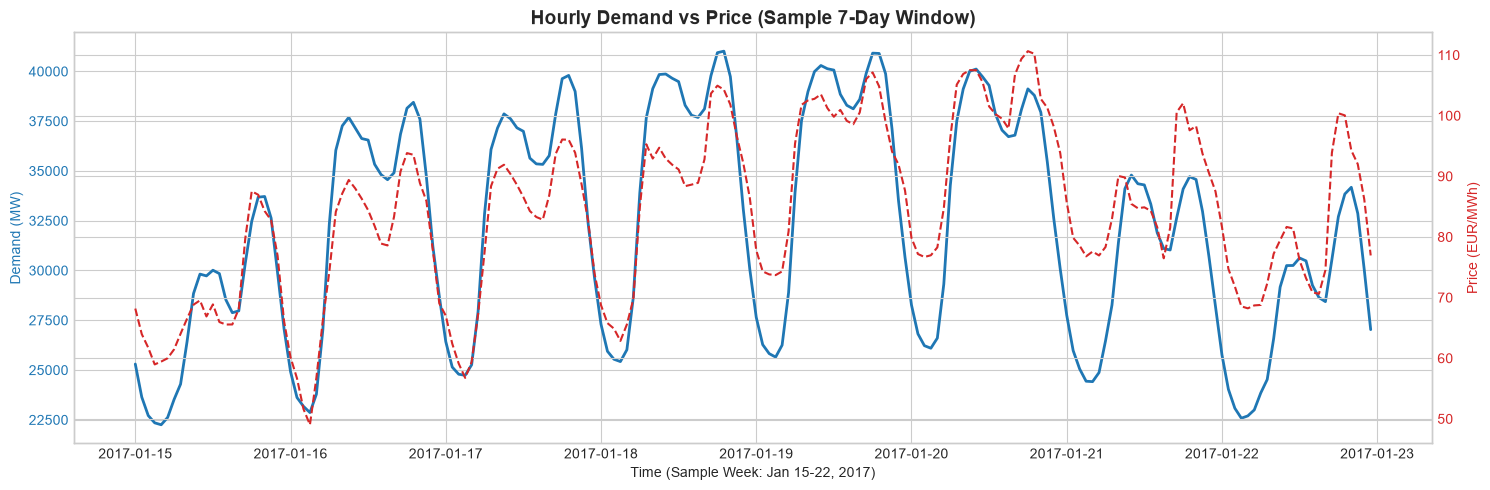

In [4]:
# Select a sample 7-day period for detailed view
sample_week = df.loc['2017-01-15':'2017-01-22']

fig, ax1 = plt.subplots(figsize=(15, 5))

color = 'tab:blue'
ax1.set_xlabel('Time (Sample Week: Jan 15-22, 2017)')
ax1.set_ylabel('Demand (MW)', color=color)
ax1.plot(sample_week.index, sample_week['total load actual'], color=color, linewidth=2, label='Demand')
ax1.tick_params(axis='y', labelcolor=color)

# Secondary Y-axis for Price
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Price (EUR/MWh)', color=color)
ax2.plot(sample_week.index, sample_week['price actual'], color=color, linestyle='--', label='Price')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Hourly Demand vs Price (Sample 7-Day Window)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.savefig('sample_week_pattern.png', dpi=300)
plt.show()

## 3. Sudden Changes & Unusual Events (Spikes & Anomalies)
*Question:* Are there extreme price spikes or sudden anomalies in electricity demand that could affect model evaluation?

Price Spike Threshold (99th percentile): 87.46 EUR/MWh
Total Hourly Spikes Detected: 351


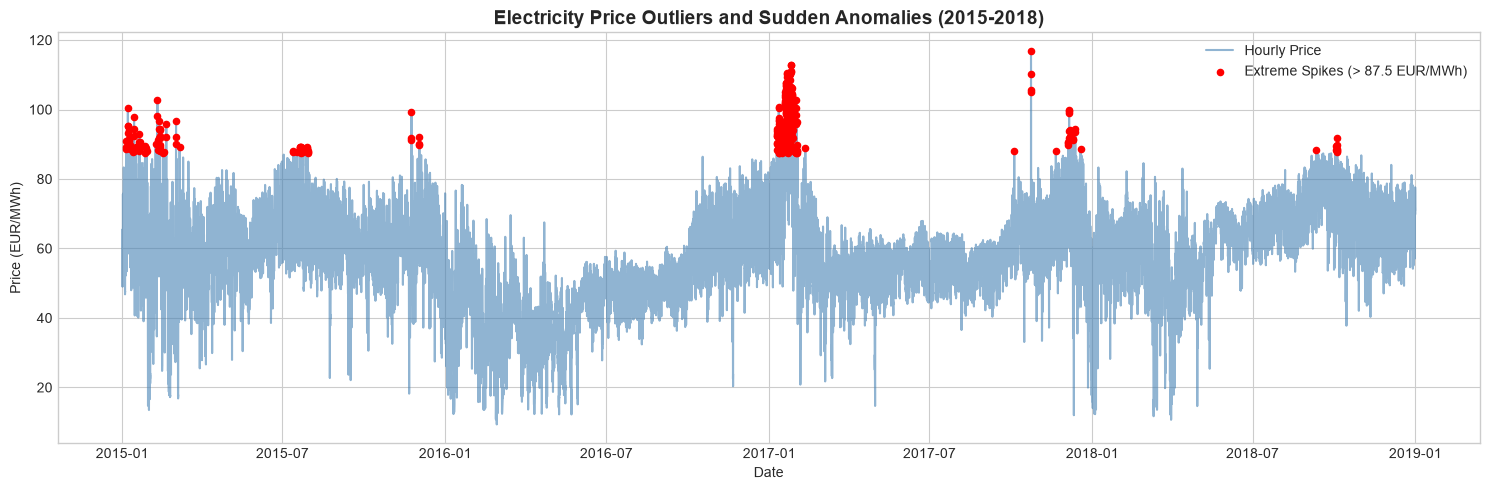

In [5]:
# Detect extreme price spikes (e.g., prices > 90th percentile or above 80 EUR/MWh)
price_threshold = df['price actual'].quantile(0.99)
spikes = df[df['price actual'] > price_threshold]

print(f"Price Spike Threshold (99th percentile): {price_threshold:.2f} EUR/MWh")
print(f"Total Hourly Spikes Detected: {len(spikes)}")

# Plotting Price Spikes and Extreme Anomalies
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['price actual'], color='steelblue', alpha=0.6, label='Hourly Price')
plt.scatter(spikes.index, spikes['price actual'], color='red', s=20, zorder=5, label=f'Extreme Spikes (> {price_threshold:.1f} EUR/MWh)')

plt.title('Electricity Price Outliers and Sudden Anomalies (2015-2018)', fontsize=14, fontweight='bold')
plt.ylabel('Price (EUR/MWh)')
plt.xlabel('Date')
plt.legend()
plt.tight_layout()
plt.savefig('unusual_events_spikes.png', dpi=300)
plt.show()

## 4. Continuity Analysis: Missing Periods & Timestamp Gaps
*Question:* Are there missing hourly records or changes in the measurement time sequence across the 4-year period?

Total Expected Hours: 35064
Total Actual Rows in Dataset: 35064
Number of Missing Hourly Timestamps: 0


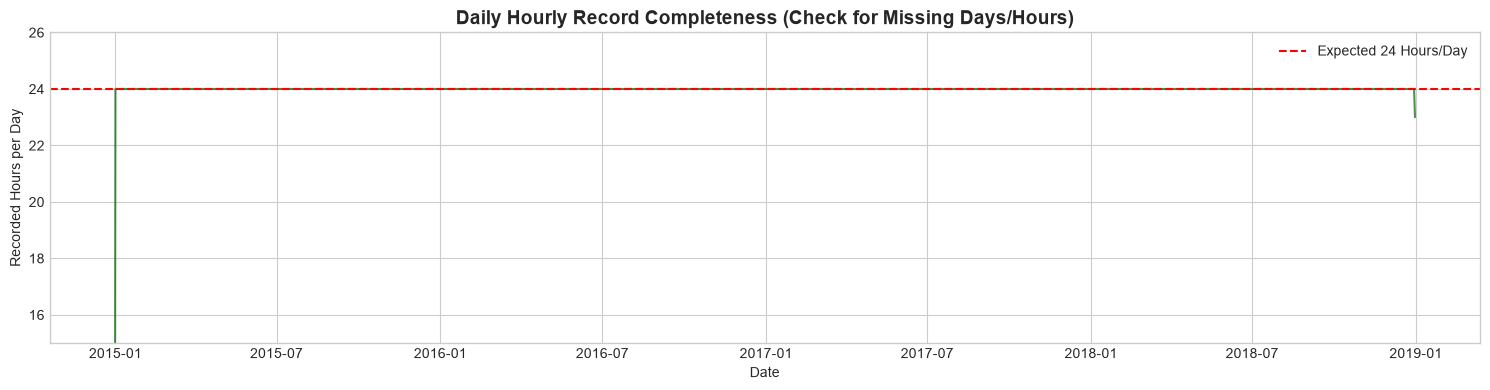

In [6]:
# Generate a complete hourly range from start date to end date
expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='h')

# Identify missing hourly timestamps
missing_timestamps = expected_range.difference(df.index)

print(f"Total Expected Hours: {len(expected_range)}")
print(f"Total Actual Rows in Dataset: {len(df)}")
print(f"Number of Missing Hourly Timestamps: {len(missing_timestamps)}")

# Plot hourly data density over time to inspect measurement consistency
hourly_counts = df.resample('D')['price actual'].count()

plt.figure(figsize=(15, 4))
plt.plot(hourly_counts.index, hourly_counts.values, color='darkgreen', alpha=0.7)
plt.axhline(24, color='red', linestyle='--', label='Expected 24 Hours/Day')

plt.title('Daily Hourly Record Completeness (Check for Missing Days/Hours)', fontsize=14, fontweight='bold')
plt.ylabel('Recorded Hours per Day')
plt.xlabel('Date')
plt.ylim(15, 26)
plt.legend()
plt.tight_layout()
plt.savefig('missing_periods_check.png', dpi=300)
plt.show()

## 5. Track B Final Findings & Recommendations 

1. **Long-Term Trend:** Electricity demand maintains strong seasonal consistency (peaks in Winter and Summer), while electricity prices exhibit high volatility.
2. **Seasonality:** Strong 24-hour daily seasonality with two clear peaks daily (around 11:00 AM and 8:00 PM UTC). Weekends show significantly lower demand compared to weekdays.
3. **Unusual Events & Spikes:** Severe price spikes exist in the dataset (exceeding 80-100 EUR/MWh). These extreme events should be evaluated using robust metrics like MAE.
4. **Data Continuity:** The time series shows stable hourly sequence frequency without major missing gaps, confirming its readiness for chronological train/validation/test splitting.